### GAT - 3 layers - diff metrics

In [3]:
import os
import random
import shutil
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import Dataset
from sklearn.metrics import confusion_matrix, classification_report
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool, GAT
import matplotlib.pyplot as plt
import numpy as np
from skimage.segmentation import slic

FILE_NAME = "GAT1"

SOURCE_DIR = r"dataset"
DATA_ROOT = "dog_split"

GRID_SIZE = (16, 16)
GRAPH_MODE = "slic_knn"

SLIC_N_SEGMENTS = 120
SLIC_COMPACTNESS = 10.0
KNN_K = 8

BATCH_SIZE = 16
HIDDEN_CHANNELS = 64
LR = 1e-3
WEIGHT_DECAY = 5e-4
NUM_EPOCHS = 100
SEED = 42

torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

from torchvision.datasets import ImageFolder

class ImageFolderNoHidden(ImageFolder):
    def find_classes(self, directory):
        classes, class_to_idx = super().find_classes(directory)
        classes = [c for c in classes if not c.startswith(".")] 
        class_to_idx = {c: i for i, c in enumerate(classes)}
        return classes, class_to_idx

def prepare_split_folders():
    if os.path.exists(DATA_ROOT):
        return
    classes = [c for c in os.listdir(SOURCE_DIR)
               if os.path.isdir(os.path.join(SOURCE_DIR, c))]
    os.makedirs(os.path.join(DATA_ROOT, "train"), exist_ok=True)
    os.makedirs(os.path.join(DATA_ROOT, "val"), exist_ok=True)
    for cls in classes:
        src_dir = os.path.join(SOURCE_DIR, cls)
        images = [f for f in os.listdir(src_dir)
                  if os.path.isfile(os.path.join(src_dir, f))]
        random.shuffle(images)
        split_idx = int(len(images) * 0.7)
        train_imgs = images[:split_idx]
        val_imgs = images[split_idx:]
        train_cls_dir = os.path.join(DATA_ROOT, "train", cls)
        val_cls_dir = os.path.join(DATA_ROOT, "val", cls)
        os.makedirs(train_cls_dir, exist_ok=True)
        os.makedirs(val_cls_dir, exist_ok=True)
        for img in train_imgs:
            shutil.copy(os.path.join(src_dir, img),
                        os.path.join(train_cls_dir, img))
        for img in val_imgs:
            shutil.copy(os.path.join(src_dir, img),
                        os.path.join(val_cls_dir, img))


def build_knn_edges(coords, k, metric="euclidean"):
    num_sp = coords.size(0)
    if num_sp <= 1:
        return torch.zeros((2, 0), dtype=torch.long)
    if metric == "euclidean":
        d = torch.cdist(coords, coords, p=2)
    elif metric == "manhattan":
        d = torch.cdist(coords, coords, p=1)
    elif metric == "cosine":
        x = F.normalize(coords, dim=1)
        sim = x @ x.t()
        d = 1.0 - sim
    else:
        d = torch.cdist(coords, coords, p=2)
    k = min(k, num_sp - 1)
    knn_idx = d.topk(k + 1, largest=False).indices[:, 1:]
    edges = []
    for i in range(num_sp):
        for j in knn_idx[i]:
            j = int(j.item())
            edges.append([i, j])
            edges.append([j, i])
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    return edge_index


class ImageToGraphTransform:
    def __init__(self,
                 mode="grid",
                 grid_size=(16, 16),
                 slic_n_segments=100,
                 slic_compactness=10.0,
                 knn_k=8,
                 knn_metric="euclidean"):
        self.mode = mode
        self.grid_h, self.grid_w = grid_size
        self.slic_n_segments = slic_n_segments
        self.slic_compactness = slic_compactness
        self.knn_k = knn_k
        self.knn_metric = knn_metric

    def __call__(self, img_tensor, label):
        if self.mode == "grid":
            return self._image_to_grid_graph(img_tensor, label)
        return self._image_to_slic_knn_graph(img_tensor, label)

    def _image_to_grid_graph(self, img_tensor, label):
        img_small = F.interpolate(
            img_tensor.unsqueeze(0),
            size=(self.grid_h, self.grid_w),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)
        C, Hs, Ws = img_small.shape
        img_flat = img_small.view(C, -1).transpose(0, 1)
        ys = torch.arange(Hs).unsqueeze(1).repeat(1, Ws).reshape(-1).float()
        xs = torch.arange(Ws).unsqueeze(0).repeat(Hs, 1).reshape(-1).float()
        ys = ys / (Hs - 1 if Hs > 1 else 1)
        xs = xs / (Ws - 1 if Ws > 1 else 1)
        pos = torch.stack([xs, ys], dim=1)
        x = torch.cat([img_flat, pos], dim=1)
        edges = []

        def nid(i, j):
            return i * Ws + j

        for i in range(Hs):
            for j in range(Ws):
                s = nid(i, j)
                if j + 1 < Ws:
                    d = nid(i, j + 1)
                    edges += [[s, d], [d, s]]
                if i + 1 < Hs:
                    d = nid(i + 1, j)
                    edges += [[s, d], [d, s]]
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        data = Data(x=x, edge_index=edge_index,
                    y=torch.tensor([label], dtype=torch.long))
        data.mode = "grid"
        data.height = Hs
        data.width = Ws
        return data

    def _image_to_slic_knn_graph(self, img_tensor, label):
        img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
        segments = slic(
            img_np,
            n_segments=self.slic_n_segments,
            compactness=self.slic_compactness,
            sigma=1.0,
            start_label=0,
            channel_axis=-1,
        )
        Hs, Ws = segments.shape
        num_sp = int(segments.max()) + 1
        feats = np.zeros((num_sp, 5), dtype=np.float32)
        cnt = np.zeros((num_sp,), dtype=np.float32)
        for i in range(Hs):
            for j in range(Ws):
                s = segments[i, j]
                cnt[s] += 1.0
                rgb = img_np[i, j, :3]
                feats[s, 0:3] += rgb
                feats[s, 3] += j / (Ws - 1 if Ws > 1 else 1)
                feats[s, 4] += i / (Hs - 1 if Hs > 1 else 1)
        cnt[cnt == 0] = 1.0
        feats[:, 0:3] /= cnt[:, None]
        feats[:, 3:5] /= cnt[:, None]
        x = torch.from_numpy(feats)
        coords = x[:, 3:5]
        edge_index = build_knn_edges(coords, self.knn_k, self.knn_metric)
        data = Data(x=x, edge_index=edge_index,
                    y=torch.tensor([label], dtype=torch.long))
        data.mode = "slic_knn"
        data.height = Hs
        data.width = Ws
        data.segments = torch.from_numpy(segments.reshape(-1)).long()
        return data


class ImageFolderGraphDataset(Dataset):
    def __init__(self, root, graph_mode="grid", knn_metric="euclidean"):
        self.base_dataset = ImageFolderNoHidden(
            root=root,
            transform=transforms.ToTensor(),
        )
        self.to_graph = ImageToGraphTransform(
            mode=graph_mode,
            grid_size=GRID_SIZE,
            slic_n_segments=SLIC_N_SEGMENTS,
            slic_compactness=SLIC_COMPACTNESS,
            knn_k=KNN_K,
            knn_metric=knn_metric,
        )

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, label = self.base_dataset[idx]
        return self.to_graph(img, label)


class GATImageClassifier(nn.Module):
    def __init__(self, in_channels, hidden, num_classes):
        super().__init__()
        self.conv1 = GAT(in_channels, hidden,1)
        self.conv2 = GAT(hidden, hidden,2)
        self.lin1 = nn.Linear(hidden, hidden)
        self.lin2 = nn.Linear(hidden, num_classes)

    def forward(self, x, edge_index, batch):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        x = global_mean_pool(x, batch)
        x = F.relu(self.lin1(x))
        return self.lin2(x)


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for data in loader:
        data = data.to(device)
        optimizer.zero_grad()
        out = model(data.x, data.edge_index, data.batch)
        loss = criterion(out, data.y.view(-1))
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.num_graphs
        pred = out.argmax(dim=1)
        correct += (pred == data.y.view(-1)).sum().item()
        total += data.num_graphs
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device, collect=False):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    ys = []
    ps = []
    for data in loader:
        data = data.to(device)
        out = model(data.x, data.edge_index, data.batch)
        loss = criterion(out, data.y.view(-1))
        total_loss += loss.item() * data.num_graphs
        pred = out.argmax(dim=1)
        correct += (pred == data.y.view(-1)).sum().item()
        total += data.num_graphs
        if collect:
            ys.extend(data.y.view(-1).cpu().tolist())
            ps.extend(pred.cpu().tolist())
    if collect:
        return total_loss / total, correct / total, ys, ps
    return total_loss / total, correct / total


import numpy as np
import matplotlib.pyplot as plt


def _ema(x, alpha=0.2):
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return x
    y = np.empty_like(x)
    y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = alpha * x[i] + (1 - alpha) * y[i - 1]
    return y


def plot_training_curves(history, prefix, smooth_alpha=0.25, mark_best="val_loss"):
    plt.rcParams.update({
        "figure.dpi": 140,
        "savefig.dpi": 200,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
        "font.size": 11,
    })

    epoki = np.arange(1, len(history["train_loss"]) + 1)

    
    if mark_best == "val_acc":
        best_idx = int(np.argmax(history["val_acc"]))
    else:
        best_idx = int(np.argmin(history["val_loss"]))
    najlepsza_epoka = best_idx + 1

    
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    tr = np.array(history["train_loss"], dtype=float)
    va = np.array(history["val_loss"], dtype=float)

    ax.plot(epoki, tr, alpha=0.35, label="training (raw)")
    ax.plot(epoki, va, alpha=0.35, label="validation (raw)")
    ax.plot(epoki, _ema(tr, smooth_alpha), linewidth=2.2,
            label=f"training (EMA α={smooth_alpha})")
    ax.plot(epoki, _ema(va, smooth_alpha), linewidth=2.2,
            label=f"validation (EMA α={smooth_alpha})")

    ax.axvline(najlepsza_epoka, linestyle="--", linewidth=1.4,
               label=f"Best epoch: {najlepsza_epoka}")

    ax.set_title("Learning Curves — Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xlim(1, len(epoki))
    ax.legend(ncol=2)

    fig.tight_layout()
    fig.savefig(f"{prefix}_loss_curve.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

    
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    tr = np.array(history["train_acc"], dtype=float)
    va = np.array(history["val_acc"], dtype=float)

    ax.plot(epoki, tr, alpha=0.35, label="training (raw)")
    ax.plot(epoki, va, alpha=0.35, label="validation (raw)")
    ax.plot(epoki, _ema(tr, smooth_alpha), linewidth=2.2,
            label=f"training (EMA α={smooth_alpha})")
    ax.plot(epoki, _ema(va, smooth_alpha), linewidth=2.2,
            label=f"validation (EMA α={smooth_alpha})")

    ax.axvline(najlepsza_epoka, linestyle="--", linewidth=1.4,
               label=f"Best epoch: {najlepsza_epoka}")

    ax.set_title("Learning Curves — Accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0.0, 1.0)
    ax.set_xlim(1, len(epoki))
    ax.legend(ncol=2)

    fig.tight_layout()
    fig.savefig(f"{prefix}_accuracy_curve.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_confusion_matrix(cm, classes, prefix, normalize=True, topk_mistakes=5):
    cm = np.array(cm, dtype=float)
    cm_raw = cm.copy()

    if normalize:
        row_sums = cm.sum(axis=1, keepdims=True)
        row_sums[row_sums == 0] = 1.0
        cm = cm / row_sums

    plt.rcParams.update({
        "figure.dpi": 140,
        "savefig.dpi": 220,
        "axes.grid": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    })

    fig, ax = plt.subplots(figsize=(7.2, 6.4))
    im = ax.imshow(cm, cmap="Blues")

    ax.set_title("Confusion Matrix" + (" (Normalized)" if normalize else ""))
    ax.set_xlabel("Prediction")
    ax.set_ylabel("True label")

    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticklabels(classes)


    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            val = cm[i, j]
            txt = f"{val:.2f}" if normalize else f"{int(cm_raw[i, j])}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=9)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Udział" if normalize else "Liczba")

    fig.tight_layout()
    fig.savefig(f"{prefix}_confusion_matrix.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

    mistakes = []
    for i in range(cm_raw.shape[0]):
        for j in range(cm_raw.shape[1]):
            if i != j and cm_raw[i, j] > 0:
                mistakes.append((int(cm_raw[i, j]), classes[i], classes[j]))
    mistakes.sort(reverse=True, key=lambda x: x[0])

    if topk_mistakes and len(mistakes) > 0:
        print(f"\nTop-{min(topk_mistakes, len(mistakes))} most frequent errors (count):")
        for cnt, t, p in mistakes[:topk_mistakes]:
            print(f"  {t} → {p}: {cnt}")


def visualize_predictions(model, dataset, classes, device, prefix, n=6, show_conf=True):
    import torch
    import torch.nn.functional as F
    import random

    idxs = random.sample(range(len(dataset)), min(n, len(dataset)))
    cols = min(3, len(idxs))
    rows = int(np.ceil(len(idxs) / cols))

    plt.rcParams.update({
        "figure.dpi": 140,
        "savefig.dpi": 220,
        "axes.grid": False,
        "font.size": 11,
    })

    fig = plt.figure(figsize=(4.2 * cols, 4.2 * rows))
    for k, idx in enumerate(idxs, 1):
        data = dataset[idx]
        d = data.to(device)

        with torch.no_grad():
            batch = torch.zeros(d.x.size(0), dtype=torch.long, device=device)
            logits = model(d.x, d.edge_index, batch)
            prob = F.softmax(logits, dim=1)
            pred = int(prob.argmax(dim=1).item())
            conf = float(prob.max(dim=1).values.item())

        if data.mode == "grid":
            img = data.x[:, :3].cpu().numpy().reshape(data.height, data.width, 3)
        else:
            H, W = data.height, data.width
            seg = data.segments.cpu().numpy().reshape(H, W)
            rgb = data.x[:, :3].cpu().numpy()
            img = np.zeros((H, W, 3), dtype=np.float32)
            for sp in range(rgb.shape[0]):
                img[seg == sp] = rgb[sp]

        img = np.clip(img, 0.0, 1.0)

        ax = plt.subplot(rows, cols, k)
        ax.imshow(img)
        t = classes[int(data.y.item())]
        p = classes[pred]
        title = f"True label: {t}\nPrediction: {p}"
        if show_conf:
            title += f" (p={conf:.2f})"
        ax.set_title(title)
        ax.axis("off")

    fig.tight_layout()
    fig.savefig(f"{prefix}_sample_predictions.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)


RUN_NAME: GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic120
Konfiguracja:
  GRAPH_MODE   : slic_knn
  NUM_EPOCHS   : 100
  BATCH_SIZE   : 16
  HIDDEN_CHANS : 64
  LR           : 0.001
  WEIGHT_DECAY : 0.0005
  SLIC_N_SEG   : 120
  KNN_K        : 8
  KNN_METRIC   : euclidean
01  train_loss=0.6971  train_acc=0.496  val_loss=0.6936  val_acc=0.500
02  train_loss=0.6955  train_acc=0.496  val_loss=0.6936  val_acc=0.500
03  train_loss=0.6936  train_acc=0.496  val_loss=0.6923  val_acc=0.500
04  train_loss=0.6936  train_acc=0.496  val_loss=0.6911  val_acc=0.520
05  train_loss=0.6922  train_acc=0.579  val_loss=0.6913  val_acc=0.551
06  train_loss=0.6919  train_acc=0.579  val_loss=0.6904  val_acc=0.551
07  train_loss=0.6946  train_acc=0.500  val_loss=0.6901  val_acc=0.592
08  train_loss=0.6904  train_acc=0.561  val_loss=0.6890  val_acc=0.582
09  train_loss=0.6899  train_acc=0.592  val_loss=0.6880  val_acc=0.571
10  train_loss=0.6895  train_acc=0.575  val_loss=0.6864  val_acc=0

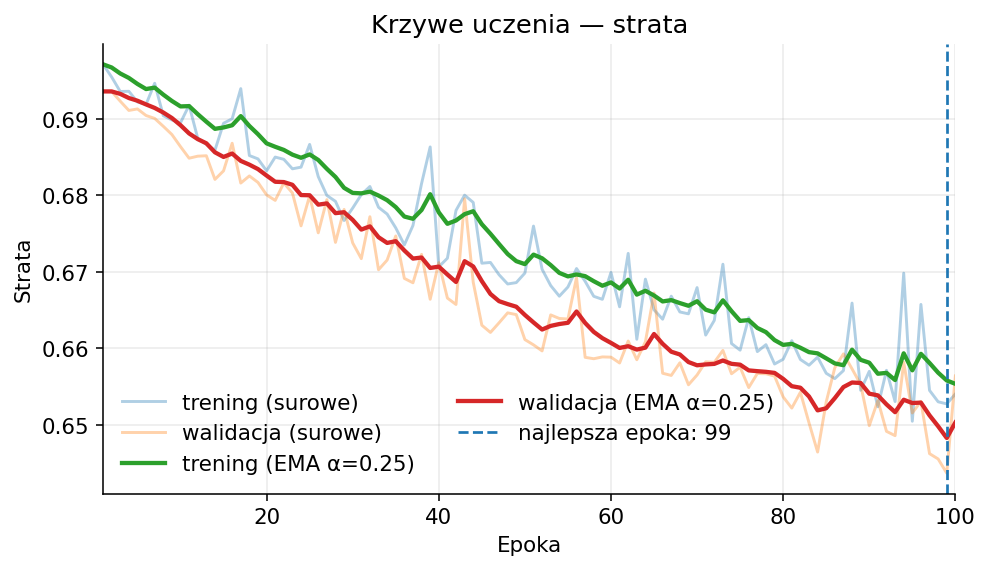

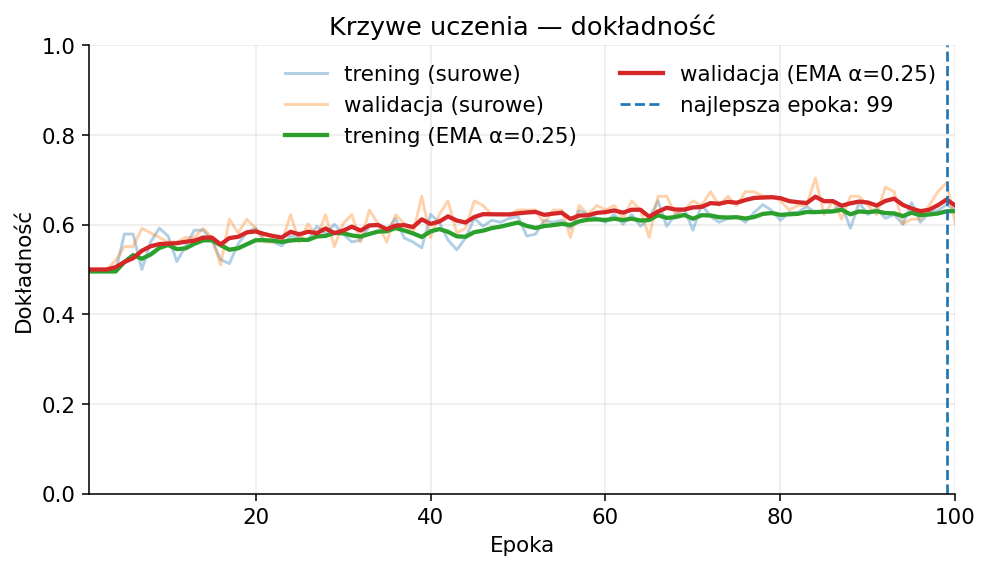


Confusion matrix:
 [[23 26]
 [13 36]]


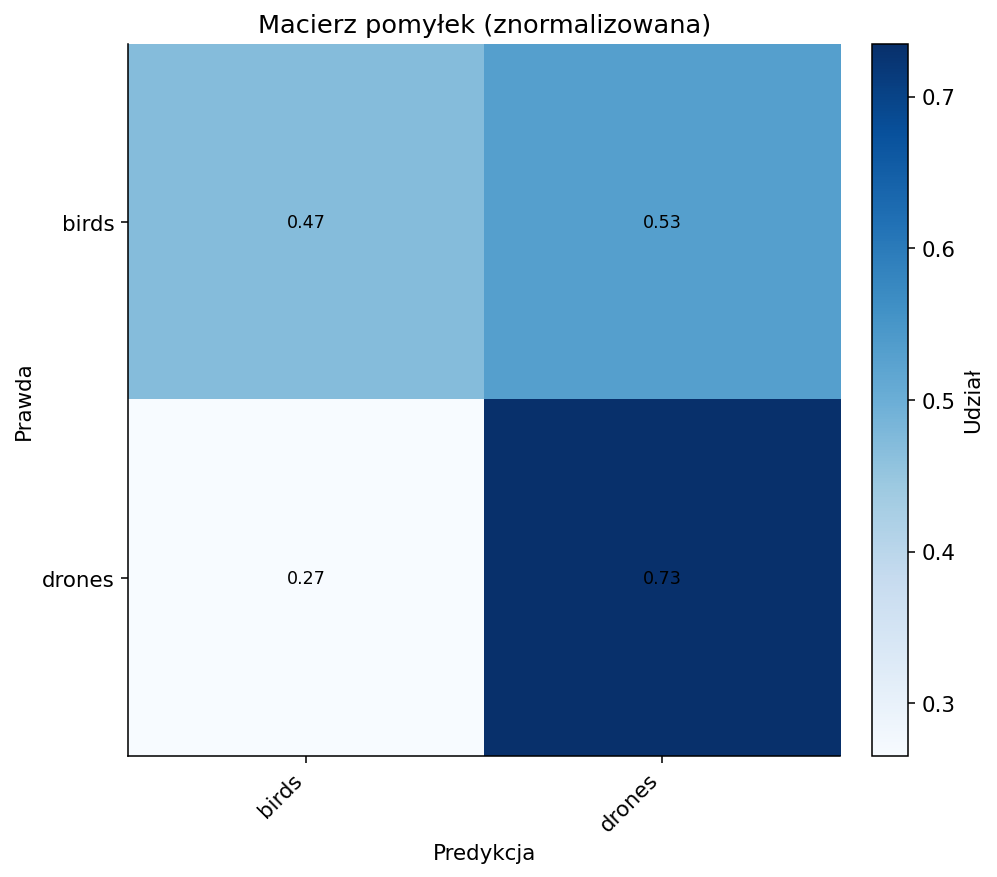


Top-2 najczęstszych pomyłek (liczba):
  birds → drones: 26
  drones → birds: 13

Classification report:
               precision    recall  f1-score   support

       birds     0.6389    0.4694    0.5412        49
      drones     0.5806    0.7347    0.6486        49

    accuracy                         0.6020        98
   macro avg     0.6098    0.6020    0.5949        98
weighted avg     0.6098    0.6020    0.5949        98



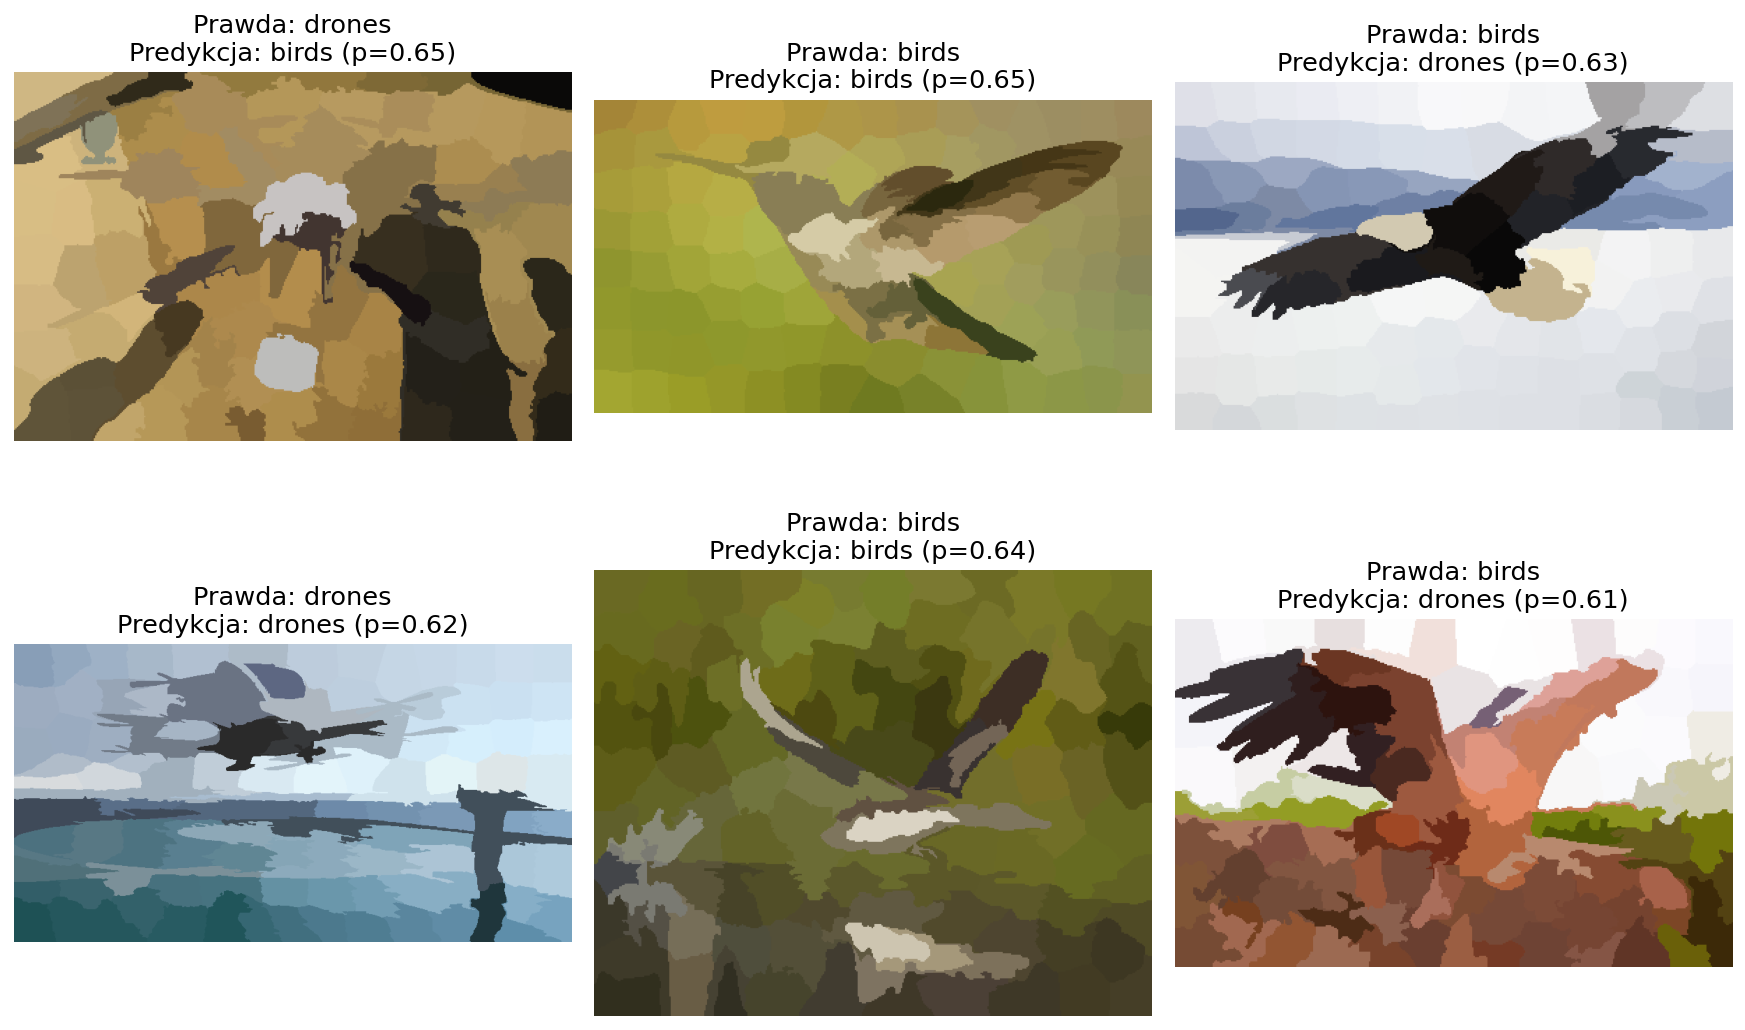


Pliki wyjściowe:
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic120_best_model.pt
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic120_loss_curve.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic120_accuracy_curve.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic120_confusion_matrix.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic120_classification_report.txt
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic120_sample_predictions.png


In [4]:
    KNN_METRIC = "euclidean"
    SLIC_N_SEGMENTS = 120
    SLIC_COMPACTNESS = 10.0
    KNN_K = 8

    if GRAPH_MODE == "slic_knn":
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_k{KNN_K}_m{KNN_METRIC}_slic{SLIC_N_SEGMENTS}"
        )
    else:
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_grid{GRID_SIZE[0]}x{GRID_SIZE[1]}"
        )

    print("RUN_NAME:", RUN_NAME)
    print("Configuration:")
    print("  GRAPH_MODE   :", GRAPH_MODE)
    print("  NUM_EPOCHS   :", NUM_EPOCHS)
    print("  BATCH_SIZE   :", BATCH_SIZE)
    print("  HIDDEN_CHANS :", HIDDEN_CHANNELS)
    print("  LR           :", LR)
    print("  WEIGHT_DECAY :", WEIGHT_DECAY)
    if GRAPH_MODE == "slic_knn":
        print("  SLIC_N_SEG   :", SLIC_N_SEGMENTS)
        print("  KNN_K        :", KNN_K)
        print("  KNN_METRIC   :", KNN_METRIC)
    else:
        print("  GRID_SIZE    :", GRID_SIZE)

    prepare_split_folders()
    train_root = os.path.join(DATA_ROOT, "train")
    val_root = os.path.join(DATA_ROOT, "val")

    train_dataset = ImageFolderGraphDataset(
        train_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )
    val_dataset = ImageFolderGraphDataset(
        val_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False
    )

    classes = train_dataset.base_dataset.classes
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GATImageClassifier(5, HIDDEN_CHANNELS, len(classes)).to(device)
    opt = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best = 0.0
    best_model_path = f"{RUN_NAME}_best_model.pt"

    for epoch in range(NUM_EPOCHS):
        tl, ta = train_one_epoch(model, train_loader, opt, crit, device)
        vl, va = evaluate(model, val_loader, crit, device)
        history["train_loss"].append(tl)
        history["train_acc"].append(ta)
        history["val_loss"].append(vl)
        history["val_acc"].append(va)
        if va > best:
            best = va
            torch.save(model.state_dict(), best_model_path)
        print(f"{epoch + 1:02d}  train_loss={tl:.4f}  "
              f"train_acc={ta:.3f}  val_loss={vl:.4f}  val_acc={va:.3f}")

    plot_training_curves(history, RUN_NAME)

    vl, va, y_true, y_pred = evaluate(
        model, val_loader, crit, device, collect=True
    )
    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion matrix:\n", cm)
    plot_confusion_matrix(cm, classes, RUN_NAME)

    report = classification_report(
        y_true, y_pred, target_names=classes, digits=4, zero_division=0
    )
    print("\nClassification report:\n", report)
    report_path = f"{RUN_NAME}_classification_report.txt"
    with open(report_path, "w", encoding="utf-8") as f:
        f.write(report)

    visualize_predictions(model, val_dataset, classes, device, RUN_NAME)

    print("\nOutput files:")
    print(" ", best_model_path)
    print(" ", f"{RUN_NAME}_loss_curve.png")
    print(" ", f"{RUN_NAME}_accuracy_curve.png")
    print(" ", f"{RUN_NAME}_confusion_matrix.png")
    print(" ", report_path)
    print(" ", f"{RUN_NAME}_sample_predictions.png")


RUN_NAME: GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic60
Konfiguracja:
  GRAPH_MODE   : slic_knn
  NUM_EPOCHS   : 100
  BATCH_SIZE   : 16
  HIDDEN_CHANS : 64
  LR           : 0.001
  WEIGHT_DECAY : 0.0005
  SLIC_N_SEG   : 60
  KNN_K        : 8
  KNN_METRIC   : euclidean
01  train_loss=0.6968  train_acc=0.496  val_loss=0.6933  val_acc=0.500
02  train_loss=0.6937  train_acc=0.496  val_loss=0.6927  val_acc=0.500
03  train_loss=0.6935  train_acc=0.469  val_loss=0.6930  val_acc=0.500
04  train_loss=0.6935  train_acc=0.504  val_loss=0.6922  val_acc=0.561
05  train_loss=0.6923  train_acc=0.566  val_loss=0.6915  val_acc=0.541
06  train_loss=0.6918  train_acc=0.531  val_loss=0.6907  val_acc=0.500
07  train_loss=0.6918  train_acc=0.553  val_loss=0.6898  val_acc=0.561
08  train_loss=0.6924  train_acc=0.522  val_loss=0.6885  val_acc=0.541
09  train_loss=0.6963  train_acc=0.469  val_loss=0.6913  val_acc=0.500
10  train_loss=0.6911  train_acc=0.535  val_loss=0.6893  val_acc=0.5

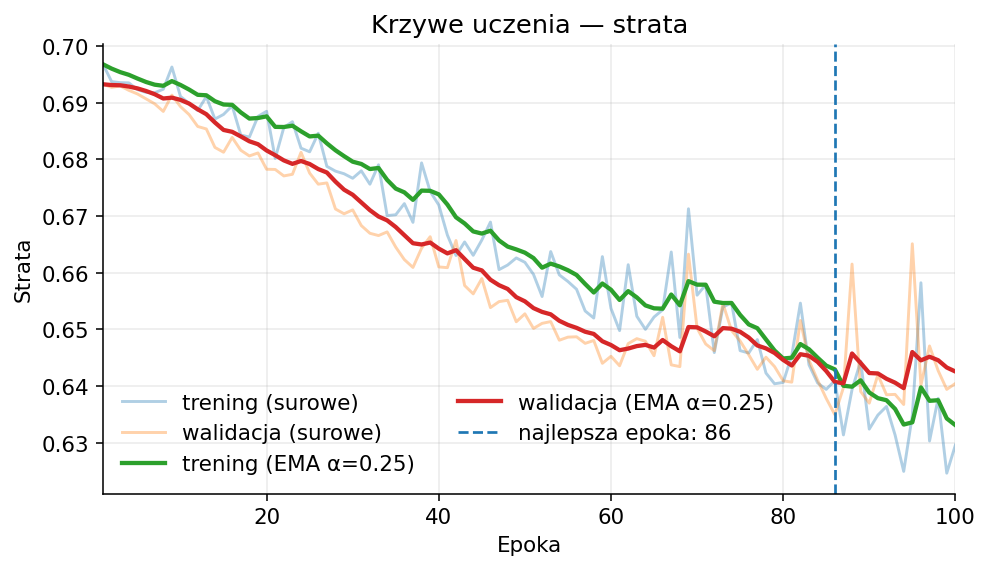

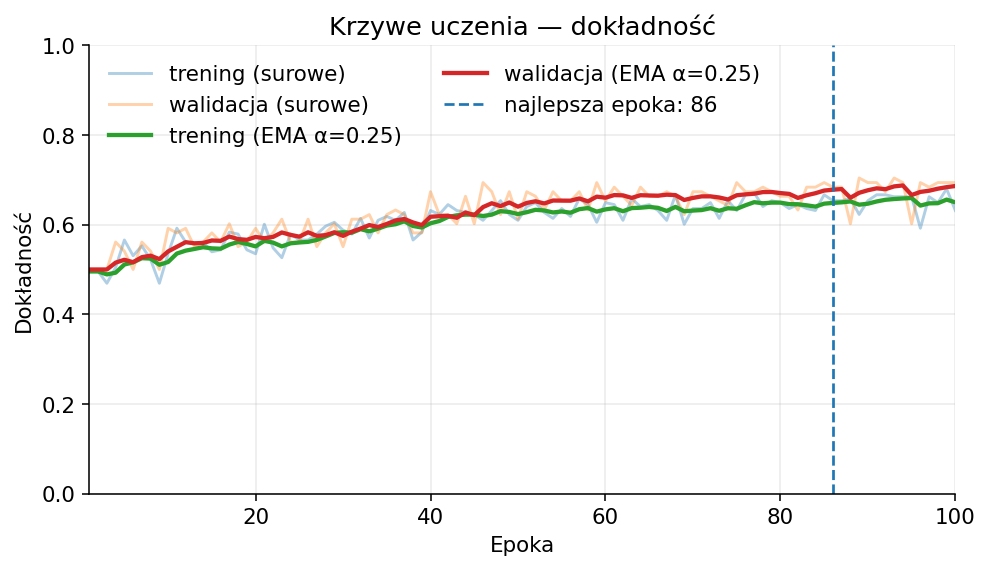


Confusion matrix:
 [[40  9]
 [21 28]]


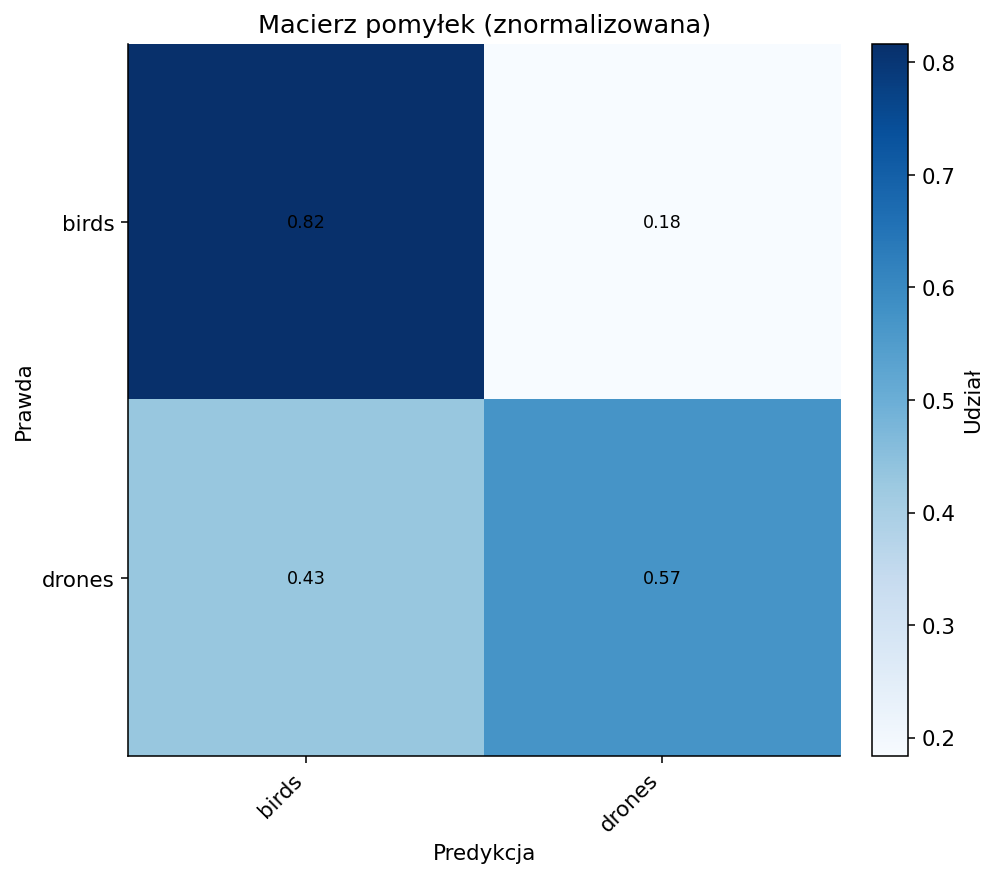


Top-2 najczęstszych pomyłek (liczba):
  drones → birds: 21
  birds → drones: 9

Classification report:
               precision    recall  f1-score   support

       birds     0.6557    0.8163    0.7273        49
      drones     0.7568    0.5714    0.6512        49

    accuracy                         0.6939        98
   macro avg     0.7062    0.6939    0.6892        98
weighted avg     0.7062    0.6939    0.6892        98



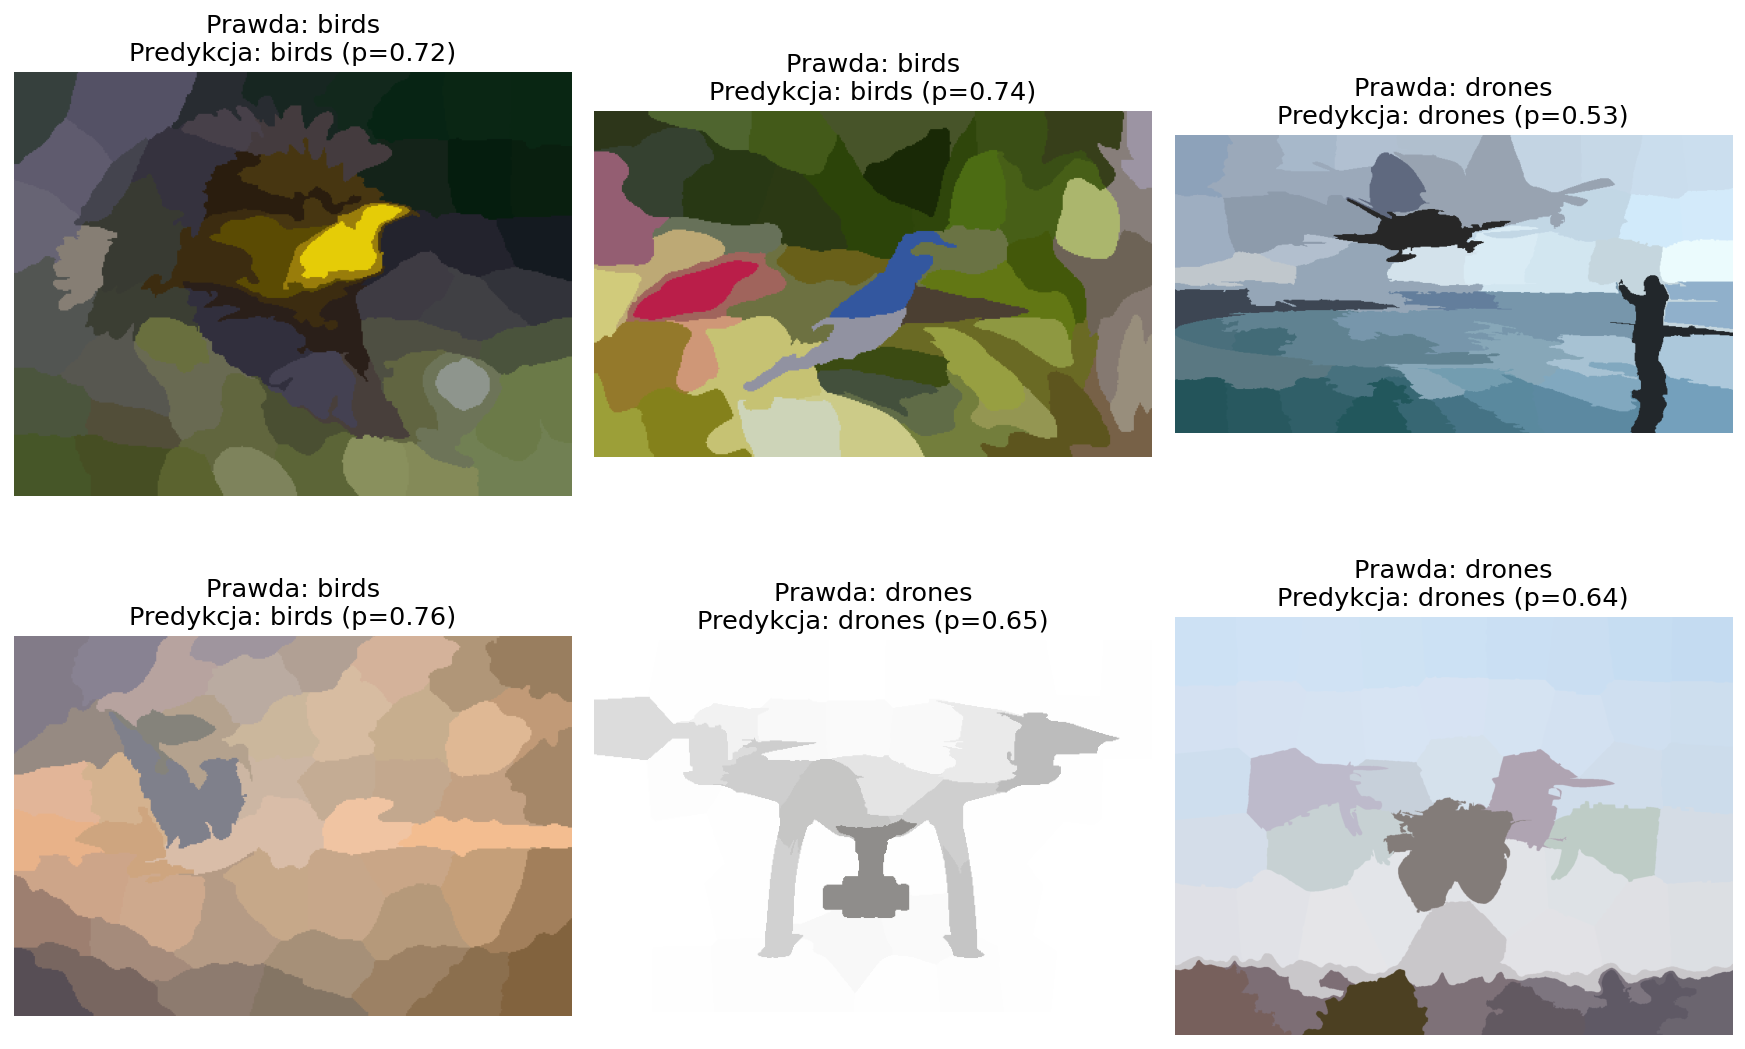


Pliki wyjściowe:
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic60_best_model.pt
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic60_loss_curve.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic60_accuracy_curve.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic60_confusion_matrix.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic60_classification_report.txt
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic60_sample_predictions.png


In [5]:
    KNN_METRIC = "euclidean"
    SLIC_N_SEGMENTS = 60
    SLIC_COMPACTNESS = 10.0
    KNN_K = 8

    if GRAPH_MODE == "slic_knn":
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_k{KNN_K}_m{KNN_METRIC}_slic{SLIC_N_SEGMENTS}"
        )
    else:
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_grid{GRID_SIZE[0]}x{GRID_SIZE[1]}"
        )

    print("RUN_NAME:", RUN_NAME)
    print("Configuration:")
    print("  GRAPH_MODE   :", GRAPH_MODE)
    print("  NUM_EPOCHS   :", NUM_EPOCHS)
    print("  BATCH_SIZE   :", BATCH_SIZE)
    print("  HIDDEN_CHANS :", HIDDEN_CHANNELS)
    print("  LR           :", LR)
    print("  WEIGHT_DECAY :", WEIGHT_DECAY)
    if GRAPH_MODE == "slic_knn":
        print("  SLIC_N_SEG   :", SLIC_N_SEGMENTS)
        print("  KNN_K        :", KNN_K)
        print("  KNN_METRIC   :", KNN_METRIC)
    else:
        print("  GRID_SIZE    :", GRID_SIZE)

    prepare_split_folders()
    train_root = os.path.join(DATA_ROOT, "train")
    val_root = os.path.join(DATA_ROOT, "val")

    train_dataset = ImageFolderGraphDataset(
        train_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )
    val_dataset = ImageFolderGraphDataset(
        val_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False
    )

    classes = train_dataset.base_dataset.classes
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GATImageClassifier(5, HIDDEN_CHANNELS, len(classes)).to(device)
    opt = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best = 0.0
    best_model_path = f"{RUN_NAME}_best_model.pt"

    for epoch in range(NUM_EPOCHS):
        tl, ta = train_one_epoch(model, train_loader, opt, crit, device)
        vl, va = evaluate(model, val_loader, crit, device)
        history["train_loss"].append(tl)
        history["train_acc"].append(ta)
        history["val_loss"].append(vl)
        history["val_acc"].append(va)
        if va > best:
            best = va
            torch.save(model.state_dict(), best_model_path)
        print(f"{epoch + 1:02d}  train_loss={tl:.4f}  "
              f"train_acc={ta:.3f}  val_loss={vl:.4f}  val_acc={va:.3f}")

    plot_training_curves(history, RUN_NAME)

    vl, va, y_true, y_pred = evaluate(
        model, val_loader, crit, device, collect=True
    )
    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion matrix:\n", cm)
    plot_confusion_matrix(cm, classes, RUN_NAME)

    report = classification_report(
        y_true, y_pred, target_names=classes, digits=4, zero_division=0
    )
    print("\nClassification report:\n", report)
    report_path = f"{RUN_NAME}_classification_report.txt"
    with open(report_path, "w", encoding="utf-8") as f:
        f.write(report)

    visualize_predictions(model, val_dataset, classes, device, RUN_NAME)

    print("\nOutput files:")
    print(" ", best_model_path)
    print(" ", f"{RUN_NAME}_loss_curve.png")
    print(" ", f"{RUN_NAME}_accuracy_curve.png")
    print(" ", f"{RUN_NAME}_confusion_matrix.png")
    print(" ", report_path)
    print(" ", f"{RUN_NAME}_sample_predictions.png")


RUN_NAME: GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic240
Konfiguracja:
  GRAPH_MODE   : slic_knn
  NUM_EPOCHS   : 100
  BATCH_SIZE   : 16
  HIDDEN_CHANS : 64
  LR           : 0.001
  WEIGHT_DECAY : 0.0005
  SLIC_N_SEG   : 240
  KNN_K        : 8
  KNN_METRIC   : euclidean
01  train_loss=0.6954  train_acc=0.456  val_loss=0.6921  val_acc=0.500
02  train_loss=0.6926  train_acc=0.504  val_loss=0.6921  val_acc=0.561
03  train_loss=0.6924  train_acc=0.544  val_loss=0.6912  val_acc=0.541
04  train_loss=0.6915  train_acc=0.575  val_loss=0.6906  val_acc=0.571
05  train_loss=0.6962  train_acc=0.478  val_loss=0.6908  val_acc=0.551
06  train_loss=0.6908  train_acc=0.531  val_loss=0.6906  val_acc=0.531
07  train_loss=0.6919  train_acc=0.518  val_loss=0.6899  val_acc=0.510
08  train_loss=0.6914  train_acc=0.579  val_loss=0.6893  val_acc=0.571
09  train_loss=0.6899  train_acc=0.579  val_loss=0.6882  val_acc=0.531
10  train_loss=0.6897  train_acc=0.557  val_loss=0.6869  val_acc=0

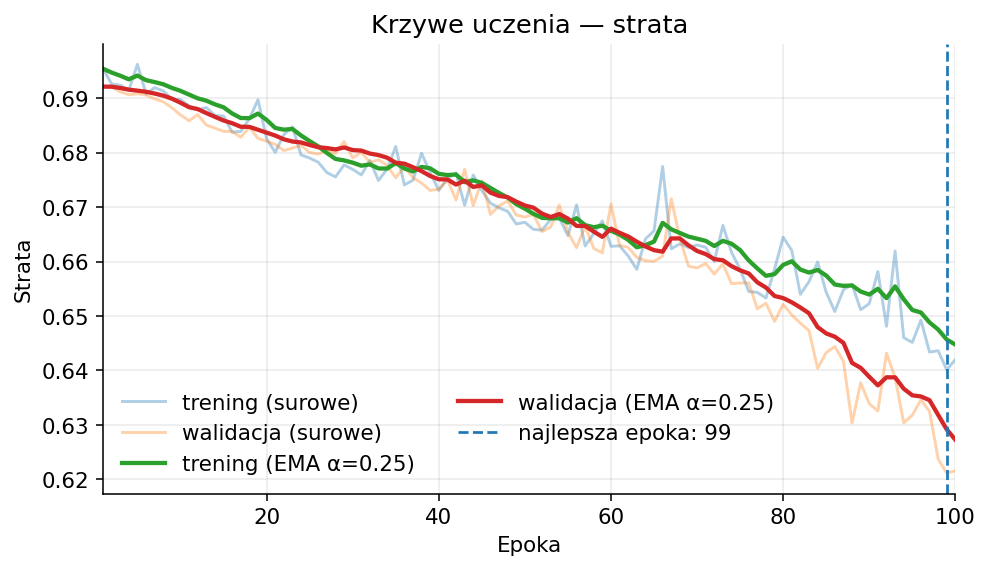

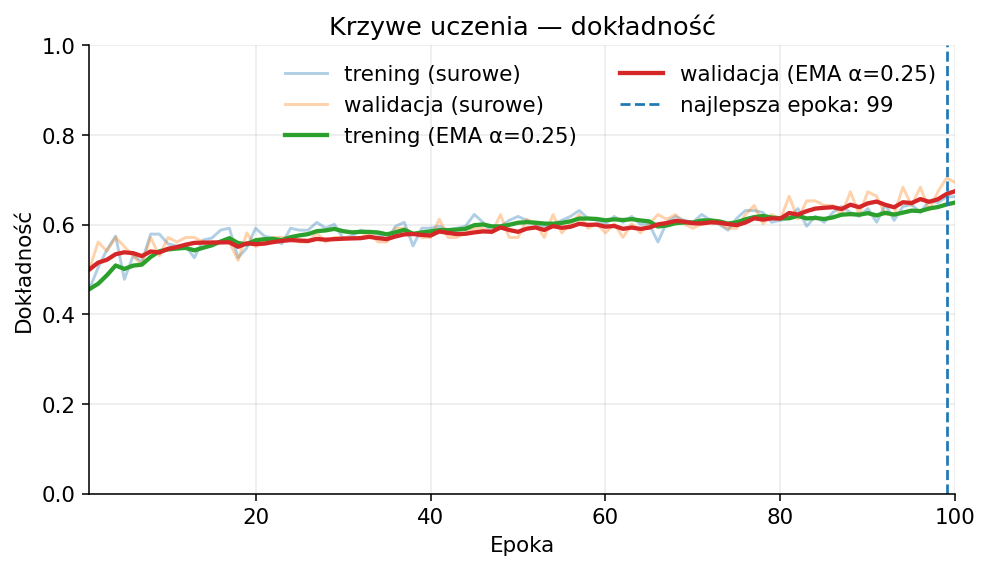


Confusion matrix:
 [[35 14]
 [16 33]]


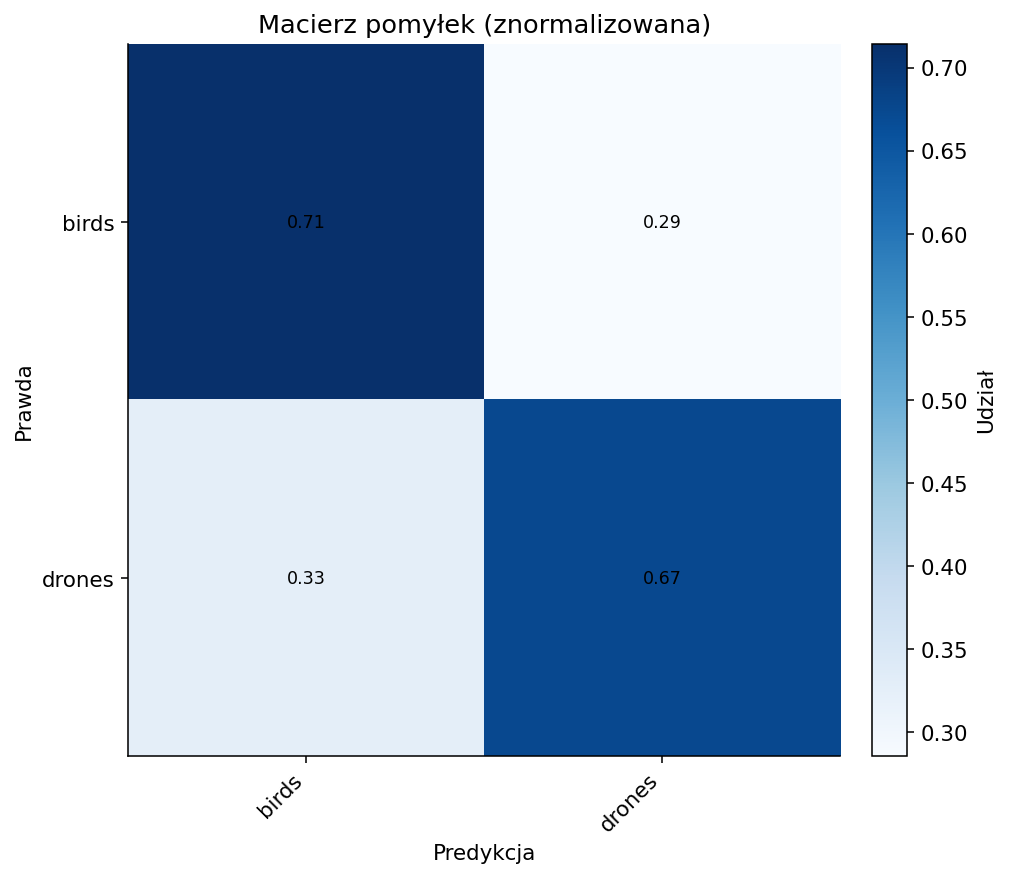


Top-2 najczęstszych pomyłek (liczba):
  drones → birds: 16
  birds → drones: 14

Classification report:
               precision    recall  f1-score   support

       birds     0.6863    0.7143    0.7000        49
      drones     0.7021    0.6735    0.6875        49

    accuracy                         0.6939        98
   macro avg     0.6942    0.6939    0.6938        98
weighted avg     0.6942    0.6939    0.6938        98



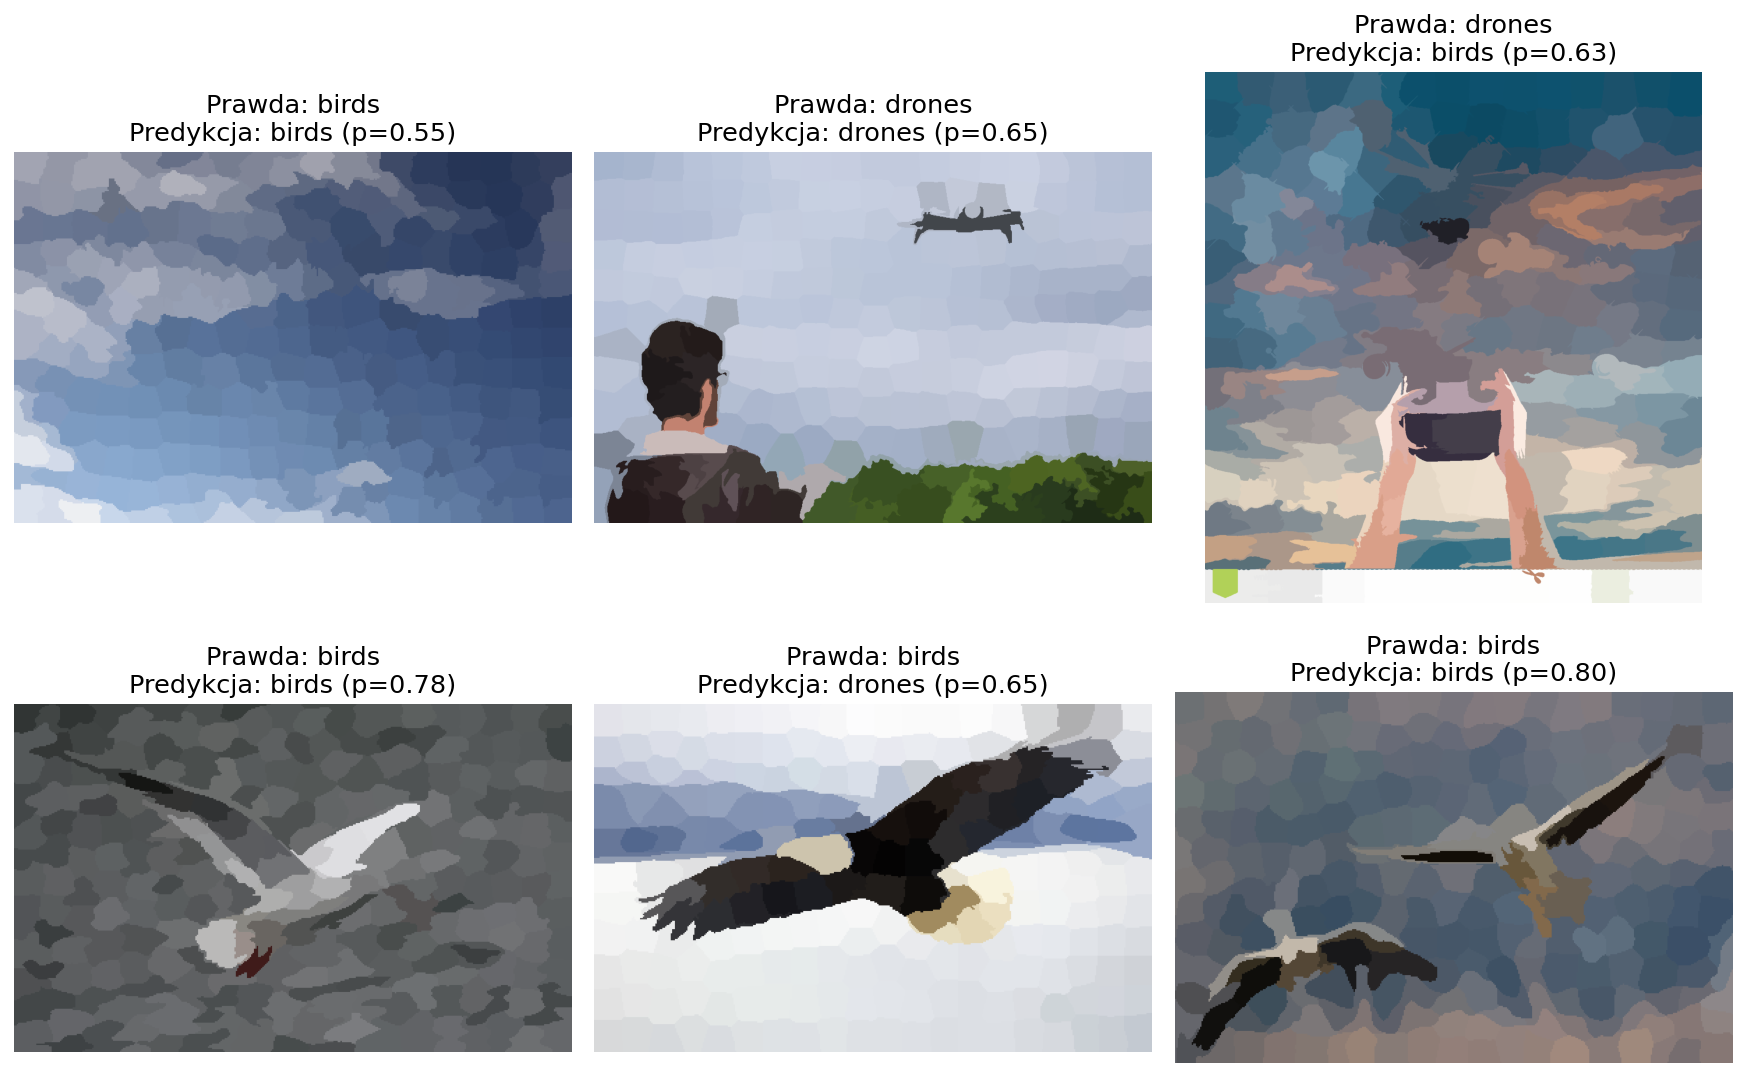


Pliki wyjściowe:
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic240_best_model.pt
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic240_loss_curve.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic240_accuracy_curve.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic240_confusion_matrix.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic240_classification_report.txt
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k8_meuclidean_slic240_sample_predictions.png


In [6]:
    KNN_METRIC = "euclidean"
    SLIC_N_SEGMENTS = 240
    SLIC_COMPACTNESS = 10.0
    KNN_K = 8

    if GRAPH_MODE == "slic_knn":
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_k{KNN_K}_m{KNN_METRIC}_slic{SLIC_N_SEGMENTS}"
        )
    else:
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_grid{GRID_SIZE[0]}x{GRID_SIZE[1]}"
        )

    print("RUN_NAME:", RUN_NAME)
    print("Configuration:")
    print("  GRAPH_MODE   :", GRAPH_MODE)
    print("  NUM_EPOCHS   :", NUM_EPOCHS)
    print("  BATCH_SIZE   :", BATCH_SIZE)
    print("  HIDDEN_CHANS :", HIDDEN_CHANNELS)
    print("  LR           :", LR)
    print("  WEIGHT_DECAY :", WEIGHT_DECAY)
    if GRAPH_MODE == "slic_knn":
        print("  SLIC_N_SEG   :", SLIC_N_SEGMENTS)
        print("  KNN_K        :", KNN_K)
        print("  KNN_METRIC   :", KNN_METRIC)
    else:
        print("  GRID_SIZE    :", GRID_SIZE)

    prepare_split_folders()
    train_root = os.path.join(DATA_ROOT, "train")
    val_root = os.path.join(DATA_ROOT, "val")

    train_dataset = ImageFolderGraphDataset(
        train_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )
    val_dataset = ImageFolderGraphDataset(
        val_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False
    )

    classes = train_dataset.base_dataset.classes
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GATImageClassifier(5, HIDDEN_CHANNELS, len(classes)).to(device)
    opt = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best = 0.0
    best_model_path = f"{RUN_NAME}_best_model.pt"

    for epoch in range(NUM_EPOCHS):
        tl, ta = train_one_epoch(model, train_loader, opt, crit, device)
        vl, va = evaluate(model, val_loader, crit, device)
        history["train_loss"].append(tl)
        history["train_acc"].append(ta)
        history["val_loss"].append(vl)
        history["val_acc"].append(va)
        if va > best:
            best = va
            torch.save(model.state_dict(), best_model_path)
        print(f"{epoch + 1:02d}  train_loss={tl:.4f}  "
              f"train_acc={ta:.3f}  val_loss={vl:.4f}  val_acc={va:.3f}")

    plot_training_curves(history, RUN_NAME)

    vl, va, y_true, y_pred = evaluate(
        model, val_loader, crit, device, collect=True
    )
    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion matrix:\n", cm)
    plot_confusion_matrix(cm, classes, RUN_NAME)

    report = classification_report(
        y_true, y_pred, target_names=classes, digits=4, zero_division=0
    )
    print("\nClassification report:\n", report)
    report_path = f"{RUN_NAME}_classification_report.txt"
    with open(report_path, "w", encoding="utf-8") as f:
        f.write(report)

    visualize_predictions(model, val_dataset, classes, device, RUN_NAME)

    print("\nOutput files:")
    print(" ", best_model_path)
    print(" ", f"{RUN_NAME}_loss_curve.png")
    print(" ", f"{RUN_NAME}_accuracy_curve.png")
    print(" ", f"{RUN_NAME}_confusion_matrix.png")
    print(" ", report_path)
    print(" ", f"{RUN_NAME}_sample_predictions.png")


RUN_NAME: GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k4_meuclidean_slic120
Konfiguracja:
  GRAPH_MODE   : slic_knn
  NUM_EPOCHS   : 100
  BATCH_SIZE   : 16
  HIDDEN_CHANS : 64
  LR           : 0.001
  WEIGHT_DECAY : 0.0005
  SLIC_N_SEG   : 120
  KNN_K        : 4
  KNN_METRIC   : euclidean
01  train_loss=0.6967  train_acc=0.496  val_loss=0.6939  val_acc=0.500
02  train_loss=0.6948  train_acc=0.496  val_loss=0.6930  val_acc=0.500
03  train_loss=0.6935  train_acc=0.496  val_loss=0.6927  val_acc=0.500
04  train_loss=0.6932  train_acc=0.496  val_loss=0.6919  val_acc=0.480
05  train_loss=0.6927  train_acc=0.522  val_loss=0.6918  val_acc=0.531
06  train_loss=0.6922  train_acc=0.504  val_loss=0.6913  val_acc=0.520
07  train_loss=0.6920  train_acc=0.526  val_loss=0.6904  val_acc=0.592
08  train_loss=0.6910  train_acc=0.570  val_loss=0.6889  val_acc=0.561
09  train_loss=0.6908  train_acc=0.588  val_loss=0.6876  val_acc=0.612
10  train_loss=0.6906  train_acc=0.553  val_loss=0.6876  val_acc=0

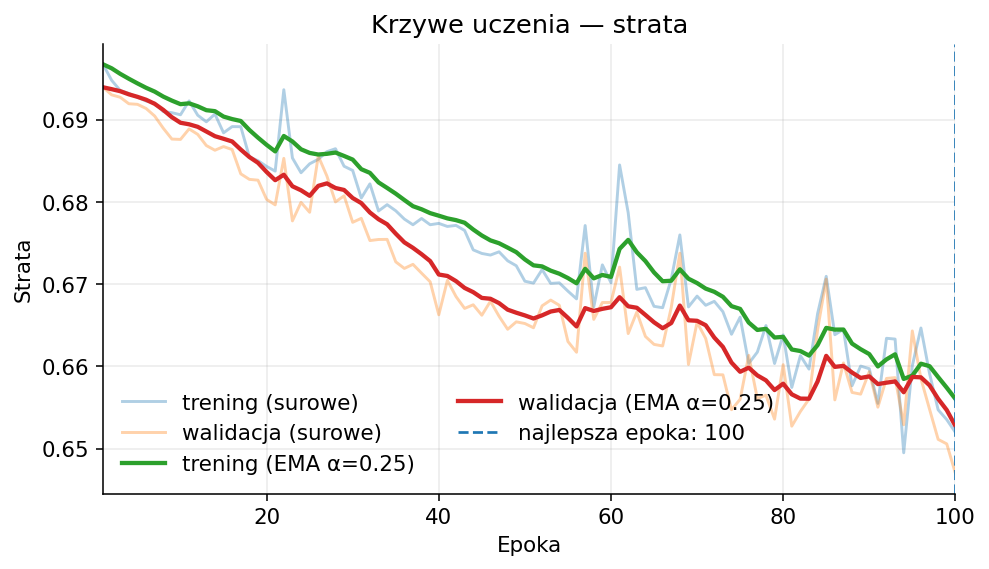

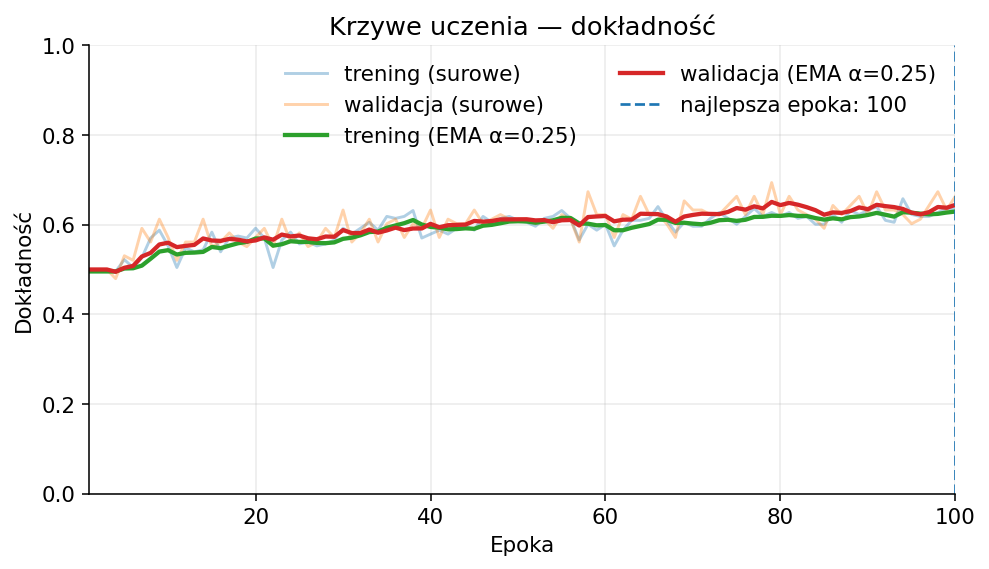


Confusion matrix:
 [[33 16]
 [17 32]]


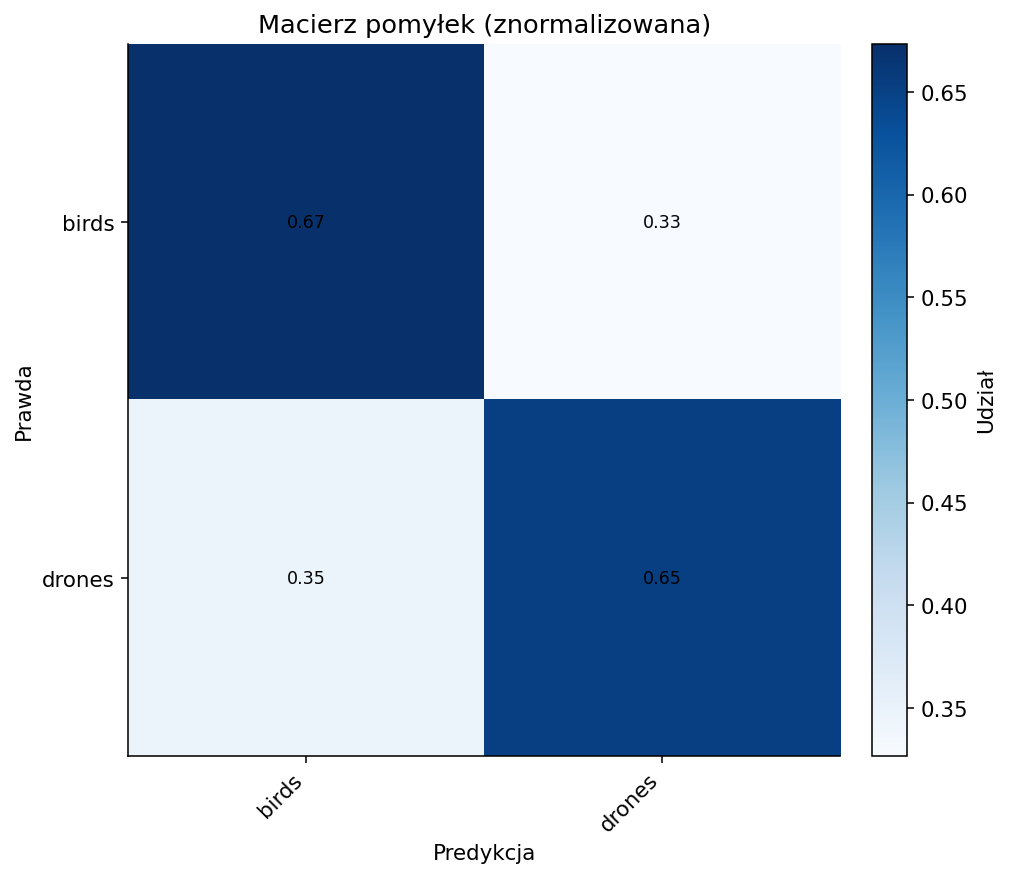


Top-2 najczęstszych pomyłek (liczba):
  drones → birds: 17
  birds → drones: 16

Classification report:
               precision    recall  f1-score   support

       birds     0.6600    0.6735    0.6667        49
      drones     0.6667    0.6531    0.6598        49

    accuracy                         0.6633        98
   macro avg     0.6633    0.6633    0.6632        98
weighted avg     0.6633    0.6633    0.6632        98



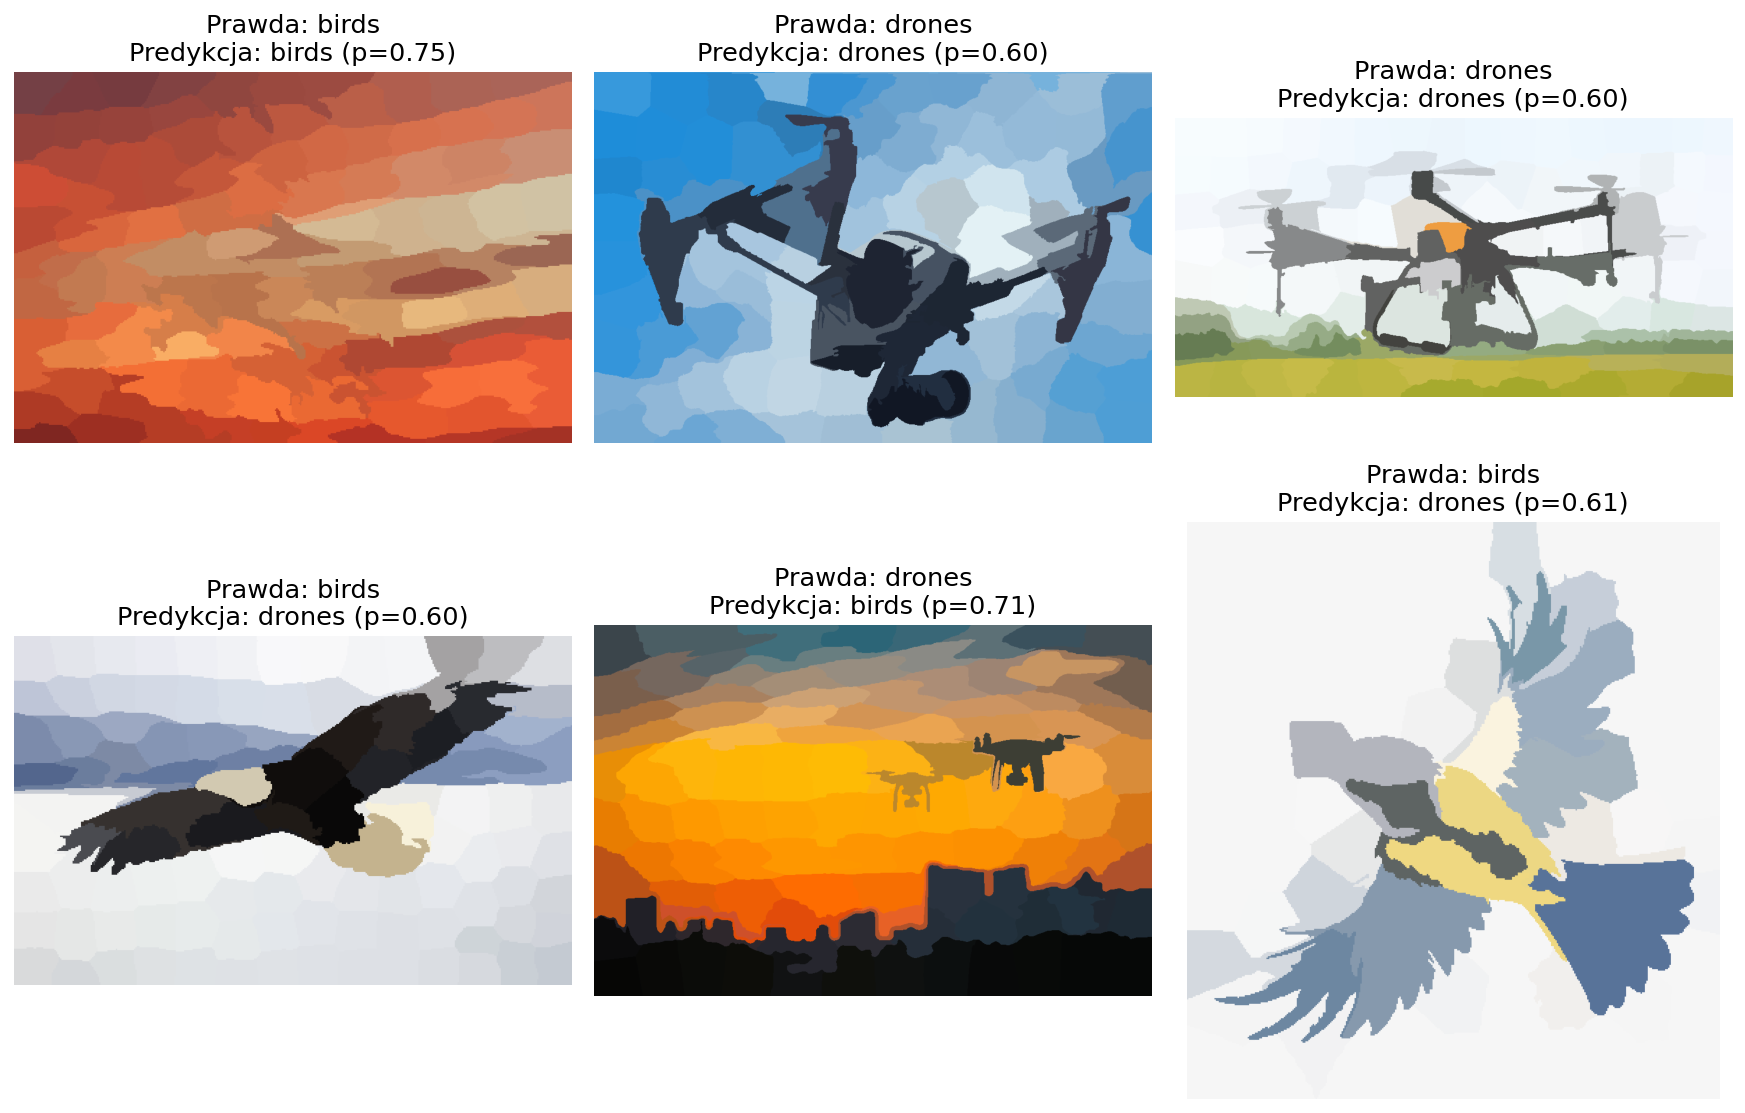


Pliki wyjściowe:
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k4_meuclidean_slic120_best_model.pt
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k4_meuclidean_slic120_loss_curve.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k4_meuclidean_slic120_accuracy_curve.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k4_meuclidean_slic120_confusion_matrix.png
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k4_meuclidean_slic120_classification_report.txt
  GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k4_meuclidean_slic120_sample_predictions.png


In [7]:
    KNN_METRIC = "euclidean"
    SLIC_N_SEGMENTS = 120
    SLIC_COMPACTNESS = 10.0
    KNN_K = 4

    if GRAPH_MODE == "slic_knn":
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_k{KNN_K}_m{KNN_METRIC}_slic{SLIC_N_SEGMENTS}"
        )
    else:
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_grid{GRID_SIZE[0]}x{GRID_SIZE[1]}"
        )

    print("RUN_NAME:", RUN_NAME)
    print("Konfiguracja:")
    print("  GRAPH_MODE   :", GRAPH_MODE)
    print("  NUM_EPOCHS   :", NUM_EPOCHS)
    print("  BATCH_SIZE   :", BATCH_SIZE)
    print("  HIDDEN_CHANS :", HIDDEN_CHANNELS)
    print("  LR           :", LR)
    print("  WEIGHT_DECAY :", WEIGHT_DECAY)
    if GRAPH_MODE == "slic_knn":
        print("  SLIC_N_SEG   :", SLIC_N_SEGMENTS)
        print("  KNN_K        :", KNN_K)
        print("  KNN_METRIC   :", KNN_METRIC)
    else:
        print("  GRID_SIZE    :", GRID_SIZE)

    prepare_split_folders()
    train_root = os.path.join(DATA_ROOT, "train")
    val_root = os.path.join(DATA_ROOT, "val")

    train_dataset = ImageFolderGraphDataset(
        train_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )
    val_dataset = ImageFolderGraphDataset(
        val_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False
    )

    classes = train_dataset.base_dataset.classes
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GATImageClassifier(5, HIDDEN_CHANNELS, len(classes)).to(device)
    opt = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best = 0.0
    best_model_path = f"{RUN_NAME}_best_model.pt"

    for epoch in range(NUM_EPOCHS):
        tl, ta = train_one_epoch(model, train_loader, opt, crit, device)
        vl, va = evaluate(model, val_loader, crit, device)
        history["train_loss"].append(tl)
        history["train_acc"].append(ta)
        history["val_loss"].append(vl)
        history["val_acc"].append(va)
        if va > best:
            best = va
            torch.save(model.state_dict(), best_model_path)
        print(f"{epoch + 1:02d}  train_loss={tl:.4f}  "
              f"train_acc={ta:.3f}  val_loss={vl:.4f}  val_acc={va:.3f}")

    plot_training_curves(history, RUN_NAME)

    vl, va, y_true, y_pred = evaluate(
        model, val_loader, crit, device, collect=True
    )
    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion matrix:\n", cm)
    plot_confusion_matrix(cm, classes, RUN_NAME)

    report = classification_report(
        y_true, y_pred, target_names=classes, digits=4, zero_division=0
    )
    print("\nClassification report:\n", report)
    report_path = f"{RUN_NAME}_classification_report.txt"
    with open(report_path, "w", encoding="utf-8") as f:
        f.write(report)

    visualize_predictions(model, val_dataset, classes, device, RUN_NAME)

    print("\nPliki wyjściowe:")
    print(" ", best_model_path)
    print(" ", f"{RUN_NAME}_loss_curve.png")
    print(" ", f"{RUN_NAME}_accuracy_curve.png")
    print(" ", f"{RUN_NAME}_confusion_matrix.png")
    print(" ", report_path)
    print(" ", f"{RUN_NAME}_sample_predictions.png")


In [ ]:
    KNN_METRIC = "euclidean"
    SLIC_N_SEGMENTS = 120
    SLIC_COMPACTNESS = 10.0
    KNN_K = 16

    if GRAPH_MODE == "slic_knn":
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_k{KNN_K}_m{KNN_METRIC}_slic{SLIC_N_SEGMENTS}"
        )
    else:
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_grid{GRID_SIZE[0]}x{GRID_SIZE[1]}"
        )

    print("RUN_NAME:", RUN_NAME)
    print("Konfiguracja:")
    print("  GRAPH_MODE   :", GRAPH_MODE)
    print("  NUM_EPOCHS   :", NUM_EPOCHS)
    print("  BATCH_SIZE   :", BATCH_SIZE)
    print("  HIDDEN_CHANS :", HIDDEN_CHANNELS)
    print("  LR           :", LR)
    print("  WEIGHT_DECAY :", WEIGHT_DECAY)
    if GRAPH_MODE == "slic_knn":
        print("  SLIC_N_SEG   :", SLIC_N_SEGMENTS)
        print("  KNN_K        :", KNN_K)
        print("  KNN_METRIC   :", KNN_METRIC)
    else:
        print("  GRID_SIZE    :", GRID_SIZE)

    prepare_split_folders()
    train_root = os.path.join(DATA_ROOT, "train")
    val_root = os.path.join(DATA_ROOT, "val")

    train_dataset = ImageFolderGraphDataset(
        train_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )
    val_dataset = ImageFolderGraphDataset(
        val_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False
    )

    classes = train_dataset.base_dataset.classes
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GATImageClassifier(5, HIDDEN_CHANNELS, len(classes)).to(device)
    opt = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best = 0.0
    best_model_path = f"{RUN_NAME}_best_model.pt"

    for epoch in range(NUM_EPOCHS):
        tl, ta = train_one_epoch(model, train_loader, opt, crit, device)
        vl, va = evaluate(model, val_loader, crit, device)
        history["train_loss"].append(tl)
        history["train_acc"].append(ta)
        history["val_loss"].append(vl)
        history["val_acc"].append(va)
        if va > best:
            best = va
            torch.save(model.state_dict(), best_model_path)
        print(f"{epoch + 1:02d}  train_loss={tl:.4f}  "
              f"train_acc={ta:.3f}  val_loss={vl:.4f}  val_acc={va:.3f}")

    plot_training_curves(history, RUN_NAME)

    vl, va, y_true, y_pred = evaluate(
        model, val_loader, crit, device, collect=True
    )
    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion matrix:\n", cm)
    plot_confusion_matrix(cm, classes, RUN_NAME)

    report = classification_report(
        y_true, y_pred, target_names=classes, digits=4, zero_division=0
    )
    print("\nClassification report:\n", report)
    report_path = f"{RUN_NAME}_classification_report.txt"
    with open(report_path, "w", encoding="utf-8") as f:
        f.write(report)

    visualize_predictions(model, val_dataset, classes, device, RUN_NAME)

    print("\nPliki wyjściowe:")
    print(" ", best_model_path)
    print(" ", f"{RUN_NAME}_loss_curve.png")
    print(" ", f"{RUN_NAME}_accuracy_curve.png")
    print(" ", f"{RUN_NAME}_confusion_matrix.png")
    print(" ", report_path)
    print(" ", f"{RUN_NAME}_sample_predictions.png")


RUN_NAME: GAT1_slic_knn_ep100_bs16_hid64_lr0.001_wd0.0005_k16_meuclidean_slic120
Konfiguracja:
  GRAPH_MODE   : slic_knn
  NUM_EPOCHS   : 100
  BATCH_SIZE   : 16
  HIDDEN_CHANS : 64
  LR           : 0.001
  WEIGHT_DECAY : 0.0005
  SLIC_N_SEG   : 120
  KNN_K        : 16
  KNN_METRIC   : euclidean
01  train_loss=0.7000  train_acc=0.504  val_loss=0.6978  val_acc=0.500
02  train_loss=0.6956  train_acc=0.504  val_loss=0.6941  val_acc=0.500
03  train_loss=0.6942  train_acc=0.504  val_loss=0.6934  val_acc=0.500
04  train_loss=0.6929  train_acc=0.504  val_loss=0.6922  val_acc=0.500
05  train_loss=0.6921  train_acc=0.504  val_loss=0.6912  val_acc=0.520
06  train_loss=0.6932  train_acc=0.469  val_loss=0.6904  val_acc=0.571
07  train_loss=0.6912  train_acc=0.539  val_loss=0.6902  val_acc=0.520
08  train_loss=0.6925  train_acc=0.504  val_loss=0.6903  val_acc=0.520
09  train_loss=0.6926  train_acc=0.500  val_loss=0.6902  val_acc=0.520
10  train_loss=0.6901  train_acc=0.544  val_loss=0.6890  val_acc

In [ ]:
    KNN_METRIC = "cosine"

    if GRAPH_MODE == "slic_knn":
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_k{KNN_K}_m{KNN_METRIC}_slic{SLIC_N_SEGMENTS}"
        )
    else:
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_grid{GRID_SIZE[0]}x{GRID_SIZE[1]}"
        )

    print("RUN_NAME:", RUN_NAME)
    print("Konfiguracja:")
    print("  GRAPH_MODE   :", GRAPH_MODE)
    print("  NUM_EPOCHS   :", NUM_EPOCHS)
    print("  BATCH_SIZE   :", BATCH_SIZE)
    print("  HIDDEN_CHANS :", HIDDEN_CHANNELS)
    print("  LR           :", LR)
    print("  WEIGHT_DECAY :", WEIGHT_DECAY)
    if GRAPH_MODE == "slic_knn":
        print("  SLIC_N_SEG   :", SLIC_N_SEGMENTS)
        print("  KNN_K        :", KNN_K)
        print("  KNN_METRIC   :", KNN_METRIC)
    else:
        print("  GRID_SIZE    :", GRID_SIZE)

    prepare_split_folders()
    train_root = os.path.join(DATA_ROOT, "train")
    val_root = os.path.join(DATA_ROOT, "val")

    train_dataset = ImageFolderGraphDataset(
        train_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )
    val_dataset = ImageFolderGraphDataset(
        val_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False
    )

    classes = train_dataset.base_dataset.classes
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GATImageClassifier(5, HIDDEN_CHANNELS, len(classes)).to(device)
    opt = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best = 0.0
    best_model_path = f"{RUN_NAME}_best_model.pt"

    for epoch in range(NUM_EPOCHS):
        tl, ta = train_one_epoch(model, train_loader, opt, crit, device)
        vl, va = evaluate(model, val_loader, crit, device)
        history["train_loss"].append(tl)
        history["train_acc"].append(ta)
        history["val_loss"].append(vl)
        history["val_acc"].append(va)
        if va > best:
            best = va
            torch.save(model.state_dict(), best_model_path)
        print(f"{epoch + 1:02d}  train_loss={tl:.4f}  "
              f"train_acc={ta:.3f}  val_loss={vl:.4f}  val_acc={va:.3f}")

    plot_training_curves(history, RUN_NAME)

    vl, va, y_true, y_pred = evaluate(
        model, val_loader, crit, device, collect=True
    )
    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion matrix:\n", cm)
    plot_confusion_matrix(cm, classes, RUN_NAME)

    report = classification_report(
        y_true, y_pred, target_names=classes, digits=4, zero_division=0
    )
    print("\nClassification report:\n", report)
    report_path = f"{RUN_NAME}_classification_report.txt"
    with open(report_path, "w", encoding="utf-8") as f:
        f.write(report)

    visualize_predictions(model, val_dataset, classes, device, RUN_NAME)

    print("\nPliki wyjściowe:")
    print(" ", best_model_path)
    print(" ", f"{RUN_NAME}_loss_curve.png")
    print(" ", f"{RUN_NAME}_accuracy_curve.png")
    print(" ", f"{RUN_NAME}_confusion_matrix.png")
    print(" ", report_path)
    print(" ", f"{RUN_NAME}_sample_predictions.png")


In [ ]:
    KNN_METRIC = "manhattan"

    if GRAPH_MODE == "slic_knn":
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_k{KNN_K}_m{KNN_METRIC}_slic{SLIC_N_SEGMENTS}"
        )
    else:
        RUN_NAME = (
            f"{FILE_NAME}_{GRAPH_MODE}_ep{NUM_EPOCHS}_bs{BATCH_SIZE}"
            f"_hid{HIDDEN_CHANNELS}_lr{LR}_wd{WEIGHT_DECAY}"
            f"_grid{GRID_SIZE[0]}x{GRID_SIZE[1]}"
        )

    print("RUN_NAME:", RUN_NAME)
    print("Konfiguracja:")
    print("  GRAPH_MODE   :", GRAPH_MODE)
    print("  NUM_EPOCHS   :", NUM_EPOCHS)
    print("  BATCH_SIZE   :", BATCH_SIZE)
    print("  HIDDEN_CHANS :", HIDDEN_CHANNELS)
    print("  LR           :", LR)
    print("  WEIGHT_DECAY :", WEIGHT_DECAY)
    if GRAPH_MODE == "slic_knn":
        print("  SLIC_N_SEG   :", SLIC_N_SEGMENTS)
        print("  KNN_K        :", KNN_K)
        print("  KNN_METRIC   :", KNN_METRIC)
    else:
        print("  GRID_SIZE    :", GRID_SIZE)

    prepare_split_folders()
    train_root = os.path.join(DATA_ROOT, "train")
    val_root = os.path.join(DATA_ROOT, "val")

    train_dataset = ImageFolderGraphDataset(
        train_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )
    val_dataset = ImageFolderGraphDataset(
        val_root, graph_mode=GRAPH_MODE, knn_metric=KNN_METRIC
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False
    )

    classes = train_dataset.base_dataset.classes
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GATImageClassifier(5, HIDDEN_CHANNELS, len(classes)).to(device)
    opt = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": []}
    best = 0.0
    best_model_path = f"{RUN_NAME}_best_model.pt"

    for epoch in range(NUM_EPOCHS):
        tl, ta = train_one_epoch(model, train_loader, opt, crit, device)
        vl, va = evaluate(model, val_loader, crit, device)
        history["train_loss"].append(tl)
        history["train_acc"].append(ta)
        history["val_loss"].append(vl)
        history["val_acc"].append(va)
        if va > best:
            best = va
            torch.save(model.state_dict(), best_model_path)
        print(f"{epoch + 1:02d}  train_loss={tl:.4f}  "
              f"train_acc={ta:.3f}  val_loss={vl:.4f}  val_acc={va:.3f}")

    plot_training_curves(history, RUN_NAME)

    vl, va, y_true, y_pred = evaluate(
        model, val_loader, crit, device, collect=True
    )
    cm = confusion_matrix(y_true, y_pred)
    print("\nConfusion matrix:\n", cm)
    plot_confusion_matrix(cm, classes, RUN_NAME)

    report = classification_report(
        y_true, y_pred, target_names=classes, digits=4, zero_division=0
    )
    print("\nClassification report:\n", report)
    report_path = f"{RUN_NAME}_classification_report.txt"
    with open(report_path, "w", encoding="utf-8") as f:
        f.write(report)

    visualize_predictions(model, val_dataset, classes, device, RUN_NAME)

    print("\nOutput Files:")
    print(" ", best_model_path)
    print(" ", f"{RUN_NAME}_loss_curve.png")
    print(" ", f"{RUN_NAME}_accuracy_curve.png")
    print(" ", f"{RUN_NAME}_confusion_matrix.png")
    print(" ", report_path)
    print(" ", f"{RUN_NAME}_sample_predictions.png")
